In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

# IMPORT LIBRARIES


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score,
    roc_curve
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [3]:

#  LOAD DATA

DATA_PATH = "/content/drive/MyDrive/ENGAGE_PROJECT/missed_appointments_data.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2000, 12)


,ID,Clinic_Code,Clinic_Day,Appointment_Date,Booking_Date,Sex,Age,Condition_Category,Phone_Available,Previous_Missed_Appointments,Attendance_Status,Appointment_Type
0,P10452,MOPC,Tuesday/Wednesday,10/21/2025,9/26/2025,Male,33,Renal condition,Yes,No,Attended,New
1,P11996,MOPC,Tuesday/Wednesday,4/8/2026,3/28/2026,Male,28,Diabetes,Yes,No,Missed,New
2,P10878,MOPC,Tuesday/Wednesday,7/29/2026,7/10/2026,Male,48,Hypertension,Yes,Yes,Missed,New
3,P11880,MOPC,Tuesday/Wednesday,6/9/2026,6/5/2026,Female,56,Other medical condition,No,No,Attended,New
4,P11002,MOPC,Tuesday/Wednesday,3/24/2026,3/3/2026,Female,35,Other medical condition,No,No,Attended,New


In [4]:

print("Missing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["Attendance_Status"].value_counts())

print("\nTarget percentages:")
display(
    df["Attendance_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Missing values:


,0
ID,0
Clinic_Code,0
Clinic_Day,0
Appointment_Date,0
Booking_Date,0
Sex,0
Age,0
Condition_Category,0
Phone_Available,0
Previous_Missed_Appointments,0



Duplicate rows: 0

Target distribution:


,count
Attendance_Status,
Attended,1200
Missed,800



Target percentages:


,proportion
Attendance_Status,
Attended,60.0
Missed,40.0



 Exploratory Data Analysis

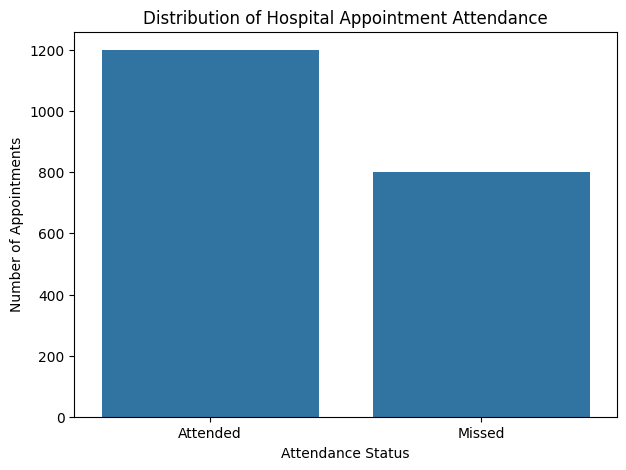

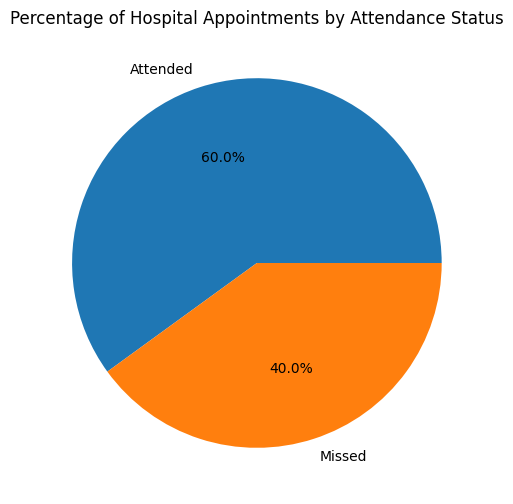

In [5]:


plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Attendance_Status")
plt.title("Distribution of Hospital Appointment Attendance")
plt.xlabel("Attendance Status")
plt.ylabel("Number of Appointments")
plt.show()


df["Attendance_Status"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6, 6)
)

plt.title("Percentage of Hospital Appointments by Attendance Status")
plt.ylabel("")

plt.show()


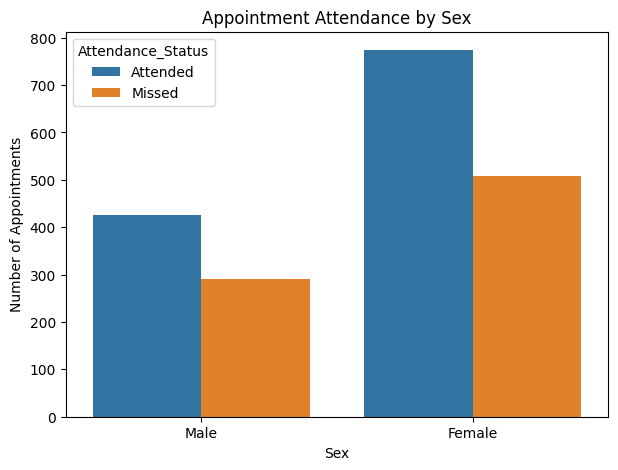

In [6]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Sex", hue="Attendance_Status")
plt.title("Appointment Attendance by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Appointments")
plt.show()

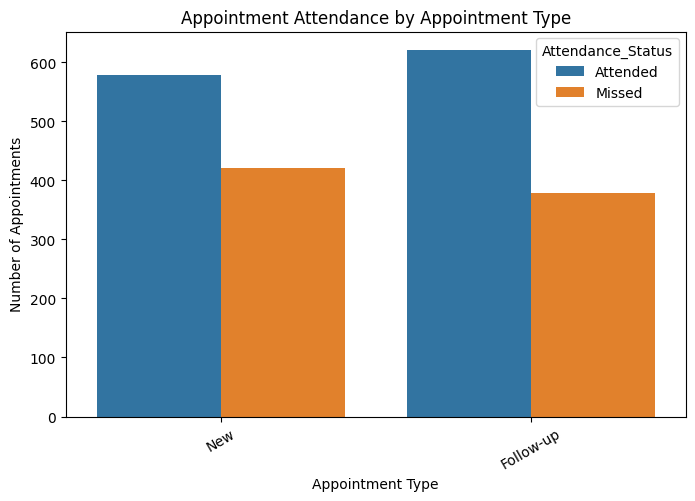

In [7]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Appointment_Type", hue="Attendance_Status")
plt.title("Appointment Attendance by Appointment Type")
plt.xlabel("Appointment Type")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=30)
plt.show()

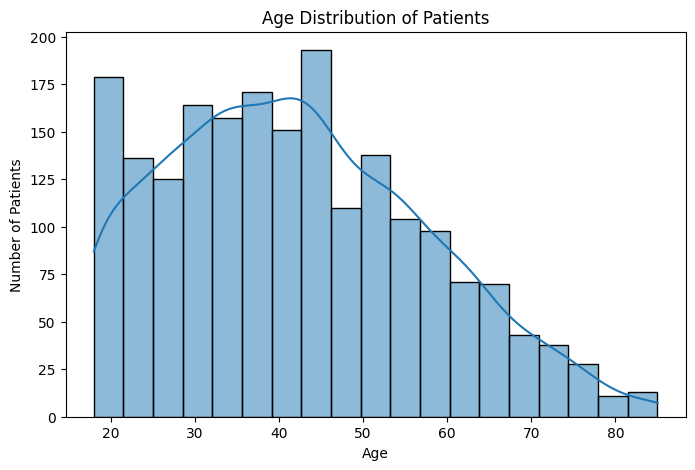

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", kde=True)
plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

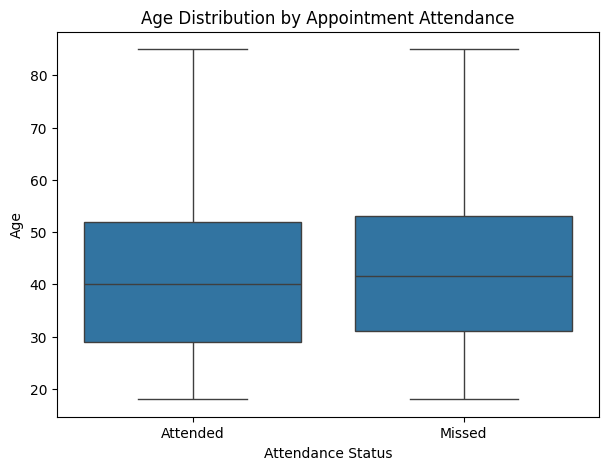

In [9]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Attendance_Status",
    y="Age"
)

plt.title("Age Distribution by Appointment Attendance")
plt.xlabel("Attendance Status")
plt.ylabel("Age")

plt.show()

In [10]:
df["Appointment_Date"] = pd.to_datetime(df["Appointment_Date"])
df["Booking_Date"] = pd.to_datetime(df["Booking_Date"])

df["Booking_Lead_Days"] = (
    df["Appointment_Date"] -
    df["Booking_Date"]
).dt.days

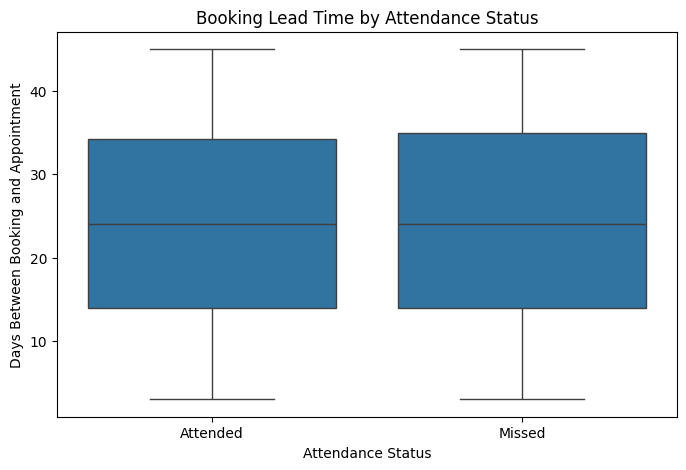

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Attendance_Status",
    y="Booking_Lead_Days"
)

plt.title("Booking Lead Time by Attendance Status")
plt.xlabel("Attendance Status")
plt.ylabel("Days Between Booking and Appointment")

plt.show()

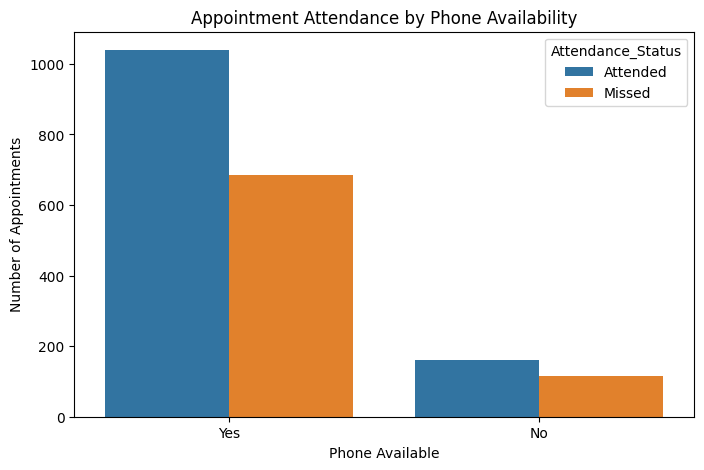

In [12]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Phone_Available", hue="Attendance_Status")
plt.title("Appointment Attendance by Phone Availability")
plt.xlabel("Phone Available")
plt.ylabel("Number of Appointments")
plt.show()

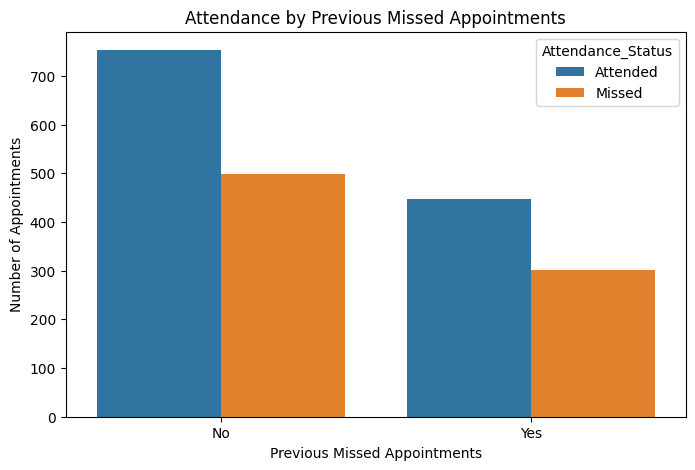

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Previous_Missed_Appointments",
    hue="Attendance_Status"
)

plt.title("Attendance by Previous Missed Appointments")
plt.xlabel("Previous Missed Appointments")
plt.ylabel("Number of Appointments")

plt.show()

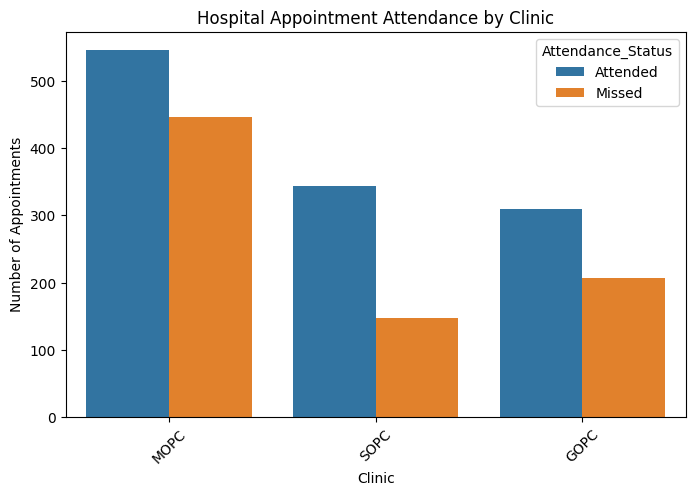

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Clinic_Code",
    hue="Attendance_Status"
)

plt.title("Hospital Appointment Attendance by Clinic")
plt.xlabel("Clinic")
plt.ylabel("Number of Appointments")

plt.xticks(rotation=45)

plt.show()

In [15]:


df_model = df.copy()

# Convert dates
df_model["Appointment_Date"] = pd.to_datetime(df_model["Appointment_Date"])
df_model["Booking_Date"] = pd.to_datetime(df_model["Booking_Date"])

# Lead time
df_model["Booking_Lead_Days"] = (
    df_model["Appointment_Date"] - df_model["Booking_Date"]
).dt.days

# Date-derived features
df_model["Appointment_Weekday"] = df_model["Appointment_Date"].dt.dayofweek
df_model["Appointment_Month"] = df_model["Appointment_Date"].dt.month
df_model["Booking_Weekday"] = df_model["Booking_Date"].dt.dayofweek

# Remove identifiers, raw dates and reminder-outcome fields
drop_columns = [
    "ID",
    "Appointment_Date",
    "Booking_Date",

]

df_model = df_model.drop(columns=drop_columns, errors="ignore")

print("Final modelling columns:")
print(df_model.columns.tolist())

display(df_model.head())

Final modelling columns:
['Clinic_Code', 'Clinic_Day', 'Sex', 'Age', 'Condition_Category', 'Phone_Available', 'Previous_Missed_Appointments', 'Attendance_Status', 'Appointment_Type', 'Booking_Lead_Days', 'Appointment_Weekday', 'Appointment_Month', 'Booking_Weekday']


,Clinic_Code,Clinic_Day,Sex,Age,Condition_Category,Phone_Available,Previous_Missed_Appointments,Attendance_Status,Appointment_Type,Booking_Lead_Days,Appointment_Weekday,Appointment_Month,Booking_Weekday
0,MOPC,Tuesday/Wednesday,Male,33,Renal condition,Yes,No,Attended,New,25,1,10,4
1,MOPC,Tuesday/Wednesday,Male,28,Diabetes,Yes,No,Missed,New,11,2,4,5
2,MOPC,Tuesday/Wednesday,Male,48,Hypertension,Yes,Yes,Missed,New,19,2,7,4
3,MOPC,Tuesday/Wednesday,Female,56,Other medical condition,No,No,Attended,New,4,1,6,4
4,MOPC,Tuesday/Wednesday,Female,35,Other medical condition,No,No,Attended,New,21,1,3,1


 Define categorical and numerical features



In [16]:

categorical_features = [
    "Clinic_Code",
    "Clinic_Day",
    "Sex",
    "Condition_Category",
    "Phone_Available",
    "Previous_Missed_Appointments",
    "Appointment_Type"
]

numerical_features = [
    "Age",
    "Booking_Lead_Days",
    "Appointment_Weekday",
    "Appointment_Month",
    "Booking_Weekday"
]

X = df_model.drop(columns=["Attendance_Status"])

y = df_model["Attendance_Status"].map({
    "Attended": 0,
    "Missed": 1
})

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nClass counts:")
print(y.value_counts())

X shape: (2000, 12)
y shape: (2000,)

Class counts:
Attendance_Status
0    1200
1     800
Name: count, dtype: int64


In [17]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training data: (1400, 12)
Testing data: (600, 12)

Training target distribution:
Attendance_Status
0    0.6
1    0.4
Name: proportion, dtype: float64

Testing target distribution:
Attendance_Status
0    0.6
1    0.4
Name: proportion, dtype: float64


In [18]:

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessor created.")

Preprocessor created.


 Compare unbalanced and balanced Logistic Regression

In [29]:
# Scale the training data using the preprocessor before fitting
X_train_scaled = preprocessor.fit_transform(X_train)

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000
)

model.fit(
    X_train_scaled,
    y_train
)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [30]:

pipeline_balanced = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    ))
])

pipeline_balanced.fit(X_train, y_train)

y_pred_balanced = pipeline_balanced.predict(X_test)
y_prob_balanced = pipeline_balanced.predict_proba(X_test)[:, 1]

print("BALANCED MODEL")
print(classification_report(y_test, y_pred_balanced, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_balanced), 4))

BALANCED MODEL
              precision    recall  f1-score   support

           0       0.61      0.46      0.52       360
           1       0.41      0.57      0.48       240

    accuracy                           0.50       600
   macro avg       0.51      0.51      0.50       600
weighted avg       0.53      0.50      0.50       600

ROC-AUC: 0.5357


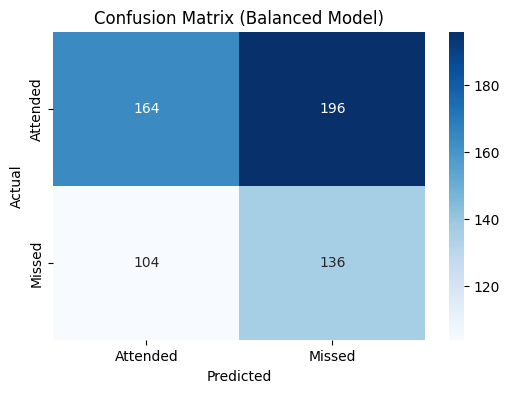

In [31]:
cm = confusion_matrix(
    y_test,
    y_pred_balanced
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Attended", "Missed"],
    yticklabels=["Attended", "Missed"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Balanced Model)")

plt.show()

In [34]:

FINAL_THRESHOLD = 0.50

def risk_category(probability):
    if probability < 0.40:
        return "Low"
    elif probability < 0.60:
        return "Moderate"
    else:
        return "High"

print("Risk categories:")
print("Low: < 40%")
print("Moderate: 40% to < 60%")
print("High: >= 60%")
print()
print("Reminder priority threshold:", FINAL_THRESHOLD)

Risk categories:
Low: < 40%
Moderate: 40% to < 60%
High: >= 60%

Reminder priority threshold: 0.5


 Save the complete final pipeline




In [35]:

FINAL_PIPELINE_PATH = "/content/missed_appointment_pipeline.pkl"
THRESHOLD_PATH = "/content/reminder_threshold.pkl"

joblib.dump(
    pipeline_balanced,
    FINAL_PIPELINE_PATH
)

joblib.dump(
    FINAL_THRESHOLD,
    THRESHOLD_PATH
)

print("Saved:")
print(FINAL_PIPELINE_PATH)
print(THRESHOLD_PATH)

Saved:
/content/missed_appointment_pipeline.pkl
/content/reminder_threshold.pkl


In [36]:
app_code = r'''
import streamlit as st
import joblib
import pandas as pd
from datetime import date, timedelta

# ------------------------------------------------------------
# Page configuration
# ------------------------------------------------------------

st.set_page_config(
    page_title="Patient Reminder Support System",
    page_icon="📅",
    layout="centered"
)

# ------------------------------------------------------------
# Load complete pipeline and threshold
# ------------------------------------------------------------

pipeline = joblib.load("missed_appointment_pipeline.pkl")
REMINDER_THRESHOLD = joblib.load("reminder_threshold.pkl")

# ------------------------------------------------------------
# Categories
# ------------------------------------------------------------

CLINICS = [
    "MOPC",
    "SOPC",
    "GOPC"
]

CLINIC_DAYS = [
    "Tuesday/Wednesday",
    "Friday",
    "Monday"
]

CONDITIONS = [
    "Renal condition",
    "Diabetes",
    "Hypertension",
    "Other medical condition",
    "Wound review",
    "Surgical consultation",
    "Pregnancy-related follow-up",
    "Gynaecological condition",
    "Respiratory condition",
    "Hernia",
    "Family planning",
    "Post-menopausal gynaecological follow-up",
    "Post-operative review",
    "Other surgical condition",
    "Menstrual/reproductive health",
    "Other"
]

APPOINTMENT_TYPES = [
    "New",
    "Follow-up"
]

WEEKDAYS = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

# ------------------------------------------------------------
# Header
# ------------------------------------------------------------

st.title("Patient Reminder Support System")

st.write(
    "This application estimates the probability of a missed "
    "appointment and supports reminder prioritisation."
)

st.info(
    "The prediction is a decision-support aid. A patient must "
    "not be denied, penalised, or deprioritised because of the prediction."
)

# ------------------------------------------------------------
# Appointment information available before the appointment
# ------------------------------------------------------------

st.subheader("Appointment Information")

clinic = st.selectbox(
    "Clinic",
    CLINICS
)

clinic_day = st.selectbox(
    "Clinic Day",
    CLINIC_DAYS
)

appointment_type = st.selectbox(
    "Appointment Type",
    APPOINTMENT_TYPES
)

condition = st.selectbox(
    "Condition Category",
    CONDITIONS
)

appointment_date = st.date_input(
    "Appointment Date",
    value=date.today() + timedelta(days=7)
)

booking_date = st.date_input(
    "Booking Date",
    value=date.today()
)

# ------------------------------------------------------------
# Patient information
# ------------------------------------------------------------

st.subheader("Patient Information")

sex = st.selectbox(
    "Sex",
    ["Female", "Male"]
)

age = st.number_input(
    "Age",
    min_value=0,
    max_value=120,
    value=30,
    step=1
)

phone_available = st.selectbox(
    "Phone Available",
    ["Yes", "No"]
)

previous_missed = st.selectbox(
    "Previous Missed Appointments",
    ["No", "Yes"]
)

# ------------------------------------------------------------
# Phone number for reminder contact
# ------------------------------------------------------------

phone_number = st.text_input(
    "Phone Number (optional)",
    placeholder="e.g. 0712345678"
)

# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

if st.button(
    "Predict Missed-Appointment Risk",
    type="primary"
):

    booking_lead_days = (
        appointment_date - booking_date
    ).days

    if booking_lead_days < 0:
        st.error(
            "Appointment Date cannot be earlier than Booking Date."
        )
        st.stop()

    appointment_weekday = appointment_date.weekday()
    appointment_month = appointment_date.month
    booking_weekday = booking_date.weekday()

    # IMPORTANT:
    # Send raw categorical values to the pipeline.
    # The pipeline performs the same One-Hot Encoding used during training.

    input_data = pd.DataFrame([{
        "Clinic_Code": clinic,
        "Clinic_Day": clinic_day,
        "Sex": sex,
        "Age": age,
        "Condition_Category": condition,
        "Phone_Available": phone_available,
        "Previous_Missed_Appointments": previous_missed,
        "Appointment_Type": appointment_type,
        "Booking_Lead_Days": booking_lead_days,
        "Appointment_Weekday": appointment_weekday,
        "Appointment_Month": appointment_month,
        "Booking_Weekday": booking_weekday
    }])

    # Calculate probability of class 1 = Missed
    probability = pipeline.predict_proba(
        input_data
    )[0, 1]

    # Reminder priority uses the selected threshold
    reminder_priority = (
        probability >= REMINDER_THRESHOLD
    )

    # Risk category is displayed separately
    if probability < 0.40:
        risk = "LOW"
    elif probability < 0.60:
        risk = "MODERATE"
    else:
        risk = "HIGH"

    # --------------------------------------------------------
    # Display prediction
    # --------------------------------------------------------

    st.subheader("Prediction Result")

    st.metric(
        "Probability of Missing Appointment",
        f"{probability:.1%}"
    )

    st.write(
        f"**Risk category:** {risk}"
    )

    st.caption(
        f"Reminder-priority threshold: "
        f"{REMINDER_THRESHOLD:.0%}"
    )

    if reminder_priority:

        st.warning(
            "Reminder priority: PRIORITISE REMINDER"
        )

        # ----------------------------------------------------
        # Reminder message
        # ----------------------------------------------------

        reminder_message = (
            f"Reminder: You have an appointment at "
            f"{clinic} on "
            f"{appointment_date.strftime('%d %B %Y')}. "
            f"Please attend your appointment as scheduled. "
            f"If you are unable to attend, please contact the "
            f"hospital to reschedule."
        )

        st.subheader("Reminder Message")

        st.text_area(
            "Message",
            reminder_message,
            height=130
        )

        # ----------------------------------------------------
        # Contact availability
        # ----------------------------------------------------

        if phone_available == "Yes":

            if phone_number.strip():

                st.success(
                    "Phone contact is available. "
                    "The reminder can be sent through the hospital's "
                    "approved messaging/SMS system."
                )

                st.write(
                    f"Contact: {phone_number}"
                )

            else:

                st.info(
                    "Phone contact is available, but no phone number "
                    "was entered. Obtain the number through the "
                    "hospital's approved records before sending."
                )

        else:

            st.info(
                "No phone contact is available. Consider an "
                "alternative reminder or follow-up mechanism."
            )

    else:

        st.success(
            "Reminder priority: STANDARD REMINDER"
        )

        standard_message = (
            f"Appointment reminder: your appointment at "
            f"{clinic} is scheduled for "
            f"{appointment_date.strftime('%d %B %Y')}. "
            f"Please attend as scheduled or contact the hospital "
            f"if you need to reschedule."
        )

        st.subheader("Standard Reminder Message")

        st.text_area(
            "Message",
            standard_message,
            height=130
        )

        if phone_available == "No":
            st.info(
                "No phone contact is available. Consider an "
                "alternative reminder or follow-up mechanism."
            )

# ------------------------------------------------------------
# Privacy note
# ------------------------------------------------------------

st.divider()

st.caption(
    "Privacy: the reminder message does not include diagnosis, "
    "condition category, age, or other unnecessary sensitive information."
)
'''

with open("/content/app.py", "w") as f:
    f.write(app_code)

print("app.py created successfully.")

app.py created successfully.


In [37]:
# Install Streamlit
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 104.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 101.8 MB/s eta 0:00:00


In [38]:
import os

required_files = [
    "/content/missed_appointment_pipeline.pkl",
    "/content/reminder_threshold.pkl",
    "/content/app.py"
]

for file_path in required_files:
    print(
        os.path.basename(file_path),
        "FOUND" if os.path.exists(file_path) else "MISSING"
    )

missed_appointment_pipeline.pkl FOUND
reminder_threshold.pkl FOUND
app.py FOUND


In [39]:
# Start Streamlit
!pkill -f "streamlit run" || true

!streamlit run /content/app.py \
    --server.address=0.0.0.0 \
    --server.port=8501 \
    --server.headless=true \
    --server.enableCORS=false \
    --server.enableXsrfProtection=false > /content/streamlit.log 2>&1 &

import time
time.sleep(4)

print(open("/content/streamlit.log").read())

^C


2026-10-08 05:40:25.979 Uvicorn server started on 0.0.0.0:8501



In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

!/content/cloudflared tunnel --url http://127.0.0.1:8501

2026-10-08T05:40:33Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-08T05:40:33Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-08T05:40:38Z INF +--------------------------------------------------------------------------------------------+
2026-10-08T05:40:38Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-08T05:40:38Z INF |  https://abstract-protecting-connecting-paper.trycloud